In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Sample Credit Card Transaction Dataset Create Panrom
np.random.seed(42)
data_size = 10000

data = {
    'Transaction_Amount': np.random.uniform(10, 5000, data_size),
    'Transaction_Time': np.random.randint(0, 24, data_size),
    'Is_International': np.random.choice([0, 1], data_size, p=[0.9, 0.1]),
    'Previous_Transactions': np.random.randint(1, 50, data_size),
    'Class': np.random.choice([0, 1], data_size, p=[0.95, 0.05]) 
}

df = pd.DataFrame(data)

print("Dataset Sample:")
df.head()

Dataset Sample:


,Transaction_Amount,Transaction_Time,Is_International,Previous_Transactions,Class
0,1878.955193,22,0,24,0
1,4754.064389,3,0,37,0
2,3662.649770,17,0,20,0
3,2997.305836,4,1,12,0
4,788.533016,15,0,20,0


In [3]:
# Features matrum Target split panrom
X = df.drop('Class', axis=1)
y = df['Class']

# Train and Test Data-va pirikrom
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data preprocessing and scaling completed successfully!")

Data preprocessing and scaling completed successfully!


In [4]:
# Model Train Panrom
model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
model.fit(X_train_scaled, y_train)

# Prediction
y_pred = model.predict(X_test_scaled)

# Evaluation Outputs
print("Model Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Model Accuracy: 0.949

Confusion Matrix:
 [[1898    4]
 [  98    0]]

Classification Report:
               precision    recall  f1-score   support

           0       0.95      1.00      0.97      1902
           1       0.00      0.00      0.00        98

    accuracy                           0.95      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.90      0.95      0.93      2000



In [5]:
# Puthiya Transaction Fraud-ah illaya nu check panrom
new_transaction = pd.DataFrame({
    'Transaction_Amount': [4800.0],
    'Transaction_Time': [2],
    'Is_International': [1],
    'Previous_Transactions': [1]
})

new_transaction_scaled = scaler.transform(new_transaction)
prediction = model.predict(new_transaction_scaled)

print("New Transaction Result:", "Fraud Detected!" if prediction[0] == 1 else "Normal Transaction")

New Transaction Result: Normal Transaction


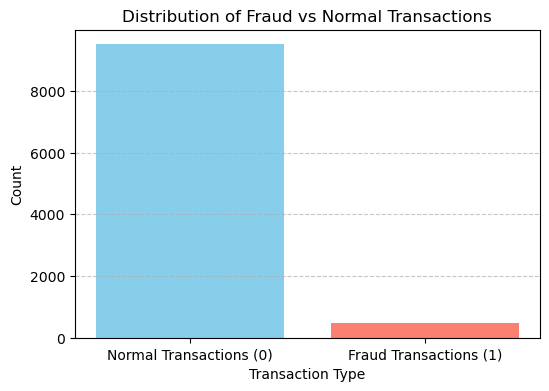

In [6]:
import matplotlib.pyplot as plt

# Fraud vs Normal Transactions Count-ah plot panrom
class_counts = df['Class'].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(
    ['Normal Transactions (0)', 'Fraud Transactions (1)'],
    class_counts,
    color=['skyblue', 'salmon']
)

plt.title('Distribution of Fraud vs Normal Transactions')
plt.xlabel('Transaction Type')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()